# E-Commerce Sales Analytics — Olist

Исследование реальных продаж, повторных покупок и связи доставки с отзывами. Полный воспроизводимый расчёт вынесен в `src/`; SQL — в `sql/`. Все денежные результаты — BRL. Источник: [Olist / Kaggle](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce), CC BY-NC-SA 4.0.

Сначала выполните `python -m src.download_data` и `python -m src.run_analysis` из корня проекта. Ячейки ниже заново строят выборки из CSV, а графики открывают из воспроизводимого отчёта.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path.cwd()
if not (ROOT / 'src').is_dir():
    ROOT = ROOT.parent
assert (ROOT / 'src').is_dir(), 'Open notebook from project root or notebooks/'
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.preprocessing import read_tables, build_order_facts, sales_sample, category_sales
from src.data_validation import profile_tables, quality_audit
from src.metrics import sales_kpis, monthly_sales, customer_metrics, segment_summary, purchase_sequence
from src.statistics import delivery_hypothesis, delivery_review_sample
pd.set_option('display.max_columns', 12)
tables = read_tables()
profile = profile_tables(tables)

## Первичное исследование

Проверяем размеры, типы, пропуски и ключи. `read_tables()` останавливает работу при нарушении жёстких контрактов. Исходные денежные поля внутри `tables` уже переведены в целые сентаво, а не BRL. Никакого заполнения дат или денежных значений средними нет.

In [2]:
display(pd.DataFrame([{'table':t,'rows':v['rows'],'columns':v['columns'],
                       'null_cells':sum(v['nulls'].values()),'exact_duplicates':v['exact_duplicates'],
                       'duplicate_keys':v['duplicate_keys']} for t,v in profile.items()]))
for name, frame in tables.items():
    display(Markdown('### ' + name))
    display(pd.DataFrame({'dtype':frame.dtypes.astype(str), 'missing':frame.isna().sum()}))

,table,rows,columns,null_cells,exact_duplicates,duplicate_keys
0,customers,99441,5,0,0,0
1,sellers,3095,4,0,0,0
2,orders,99441,8,4908,0,0
3,products,32951,9,2448,0,0
4,order_items,112650,7,0,0,0
5,order_payments,103886,5,0,0,0
6,order_reviews,99224,7,145903,0,0
7,category_translation,71,2,0,0,0


### customers

,dtype,missing
customer_id,string,0
customer_unique_id,string,0
customer_zip_code_prefix,string,0
customer_city,string,0
customer_state,string,0


### sellers

,dtype,missing
seller_id,string,0
seller_zip_code_prefix,string,0
seller_city,string,0
seller_state,string,0


### orders

... (7 outputs left out)

### order_reviews

,dtype,missing
review_id,string,0
order_id,string,0
review_score,Int64,0
review_comment_title,string,87656
review_comment_message,string,58247
review_creation_date,datetime64[ns],0
review_answer_timestamp,datetime64[ns],0


### category_translation

,dtype,missing
product_category_name,string,0
product_category_name_english,string,0


In [3]:
display(pd.DataFrame(profile['orders']['date_ranges']).T)
display(tables['orders']['order_status'].value_counts().rename_axis('status').to_frame('orders'))
display(tables['order_items'][['price', 'freight_value']].describe().rename_axis('statistic'))

,min,max
order_purchase_timestamp,2016-09-04 21:15:19,2018-10-17 17:30:18
order_approved_at,2016-09-15 12:16:38,2018-09-03 17:40:06
order_delivered_carrier_date,2016-10-08 10:34:01,2018-09-11 19:48:28
order_delivered_customer_date,2016-10-11 13:46:32,2018-10-17 13:22:46
order_estimated_delivery_date,2016-09-30 00:00:00,2018-11-12 00:00:00


,orders
status,
delivered,96478
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2


,price,freight_value
statistic,,
count,112650.000000,112650.000000
mean,12065.373901,1999.031993
std,18363.392805,1580.640541
min,85.000000,0.000000
25%,3990.000000,1308.000000
50%,7499.000000,1626.000000
75%,13490.000000,2115.000000
max,673500.000000,40968.000000


## Аналитическая модель и качество

Для продаж выбираем доставленные заказы с позициями. Сначала агрегируем отдельно позиции и платежи по order_id, выбираем последний отзыв, затем соединяем. `review_id` не уникален; ключ отзывов — пара order_id/review_id. Ни суммы платежей, ни доставка не прибавляются к товарному GMV.

Мягкие аномалии сохраняются в аудите: отсутствие даты получения не исключает заказ из продаж, но исключает из анализа сроков. Платёжные расхождения не исправляются без дополнительных данных.

In [4]:
facts = build_order_facts(tables)
sales = sales_sample(facts)
assert facts.order_id.is_unique and len(facts) == len(tables['orders'])
quality = quality_audit(tables, facts)
display(quality)
display(pd.Series(sales_kpis(sales), name='value').to_frame())

,check,count
0,delivered_missing_timestamp,8
1,delivery_before_purchase,0
2,carrier_before_purchase,166
3,approval_before_purchase,0
4,orders_without_items,775
5,orders_without_payments,1
6,payment_total_mismatch_gt_1_cent,303
7,orders_multiple_review_rows,547
8,review_id_reused,814
9,products_missing_category,610


,value
orders,9.647800e+04
product_gmv_brl,1.322150e+07
aov_brl,1.370416e+02
mean_items_per_order,1.142198e+00
customers,9.335800e+04


## Продажи и ассортимент

GMV = сумма цены товаров без доставки. AOV = GMV / число заказов. Месяц относится к покупке; delivered — финальный статус из выгрузки. Внутренние пустые месяцы показаны с нулём, MoM после нулевого месяца — неопределён. Последние месяцы могут быть цензурированы статусом доставки. Причины пиков без маркетингового календаря не устанавливаются.

,month,revenue,orders,aov,items_per_order,revenue_mom_pct,orders_mom_pct
0,2016-09-01,134.97,1,134.97,3.0,NaN,NaN
1,2016-10-01,40325.11,265,152.17,1.18,29777.09,26400.00
2,2016-11-01,0.00,0,NaN,<NA>,-100.00,-100.00
3,2016-12-01,10.90,1,10.90,1.0,NaN,NaN
4,2017-01-01,111798.36,750,149.06,1.22,1025573.03,74900.00
5,2017-02-01,234223.40,1653,141.70,1.12,109.51,120.40
6,2017-03-01,359198.85,2546,141.08,1.14,53.36,54.02
7,2017-04-01,340669.68,2303,147.92,1.12,-5.16,-9.54
8,2017-05-01,489338.25,3546,138.00,1.13,43.64,53.97
9,2017-06-01,421923.37,3135,134.58,1.11,-13.78,-11.59


,category,revenue_cents,items,orders,revenue
0,health_beauty,123313172,9465,8647,1233131.72
1,watches_gifts,116617698,5859,5495,1166176.98
2,bed_bath_table,102343476,10953,9272,1023434.76
3,sports_leisure,95485255,8431,7530,954852.55
4,computers_accessories,88872461,7644,6530,888724.61
5,furniture_decor,71192769,8160,6307,711927.69
6,housewares,61562869,6795,5743,615628.69
7,cool_stuff,61020410,3718,3559,610204.10
8,auto,57896665,4140,3810,578966.65
9,toys,47128648,4030,3804,471286.48


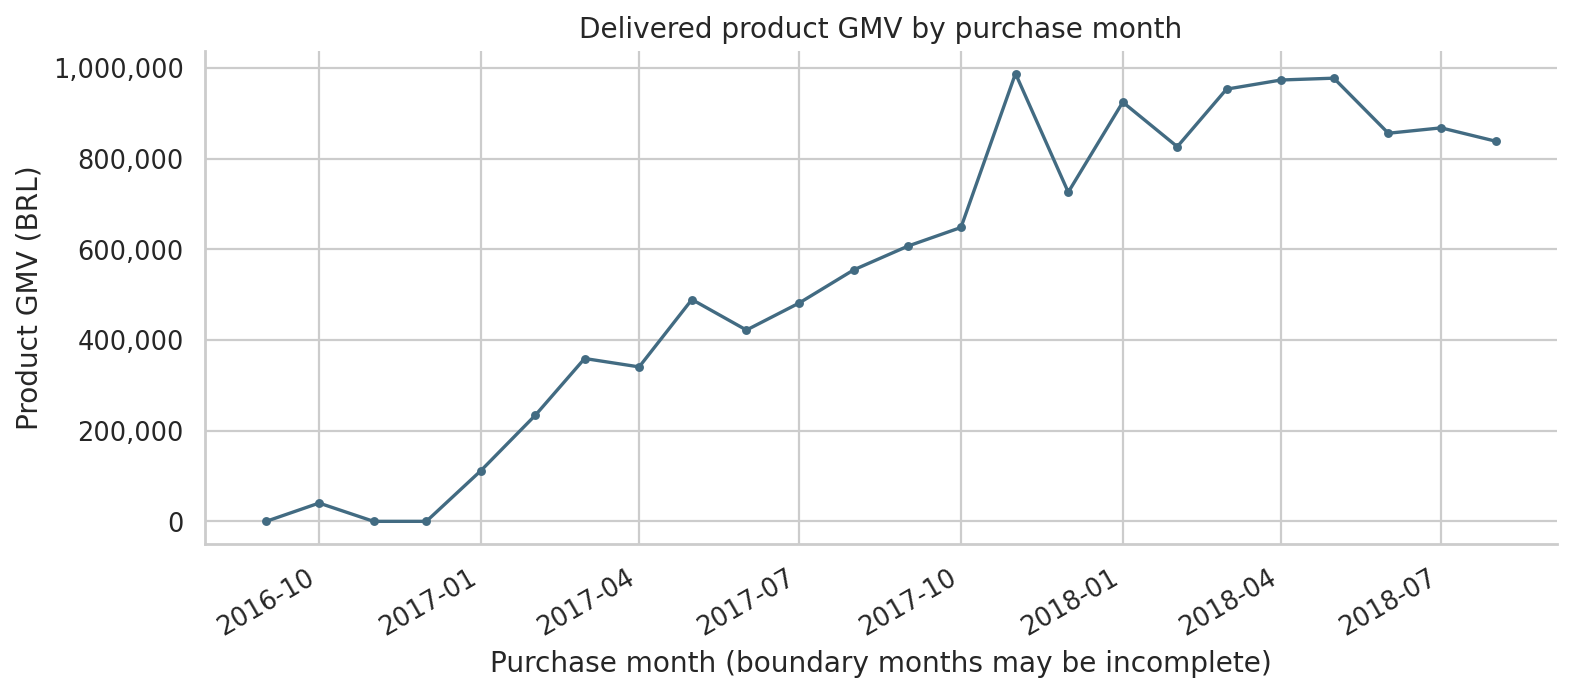

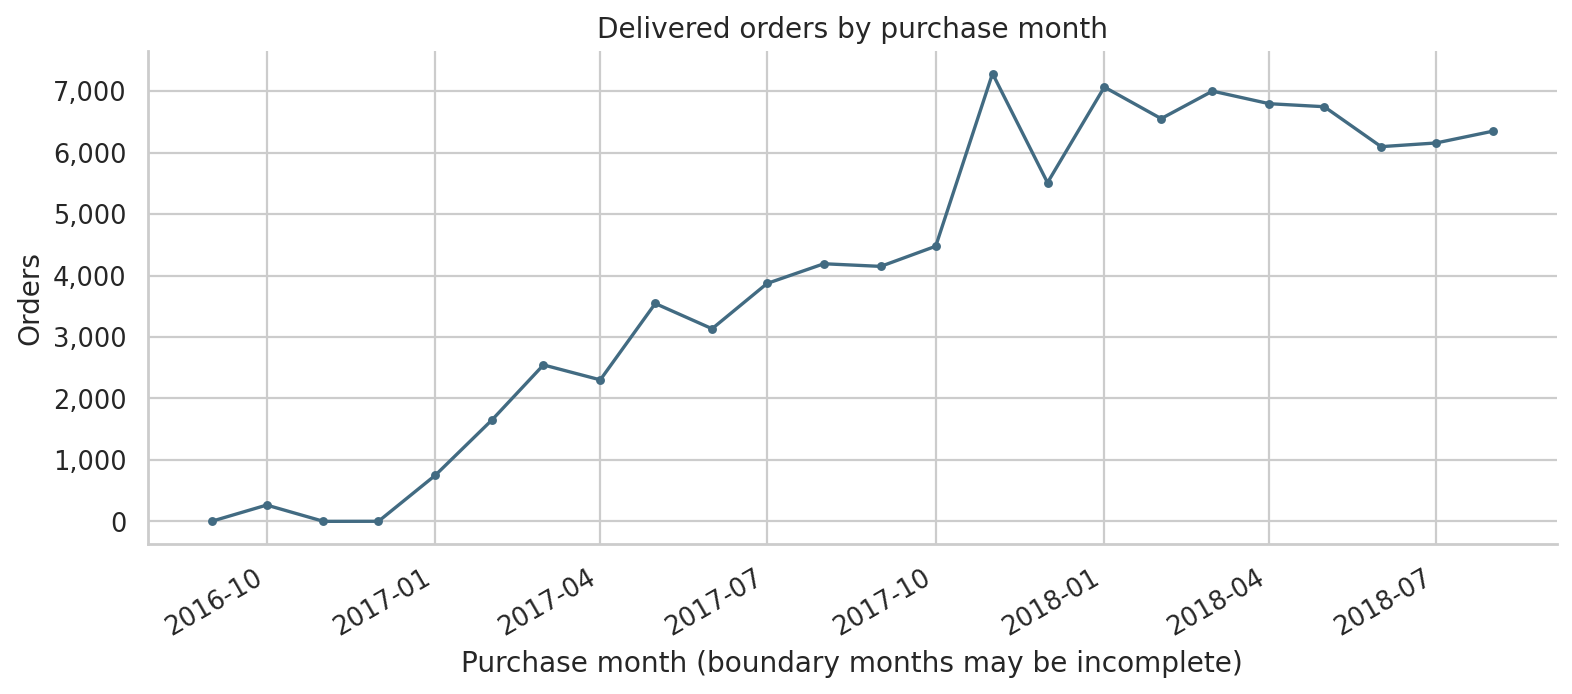

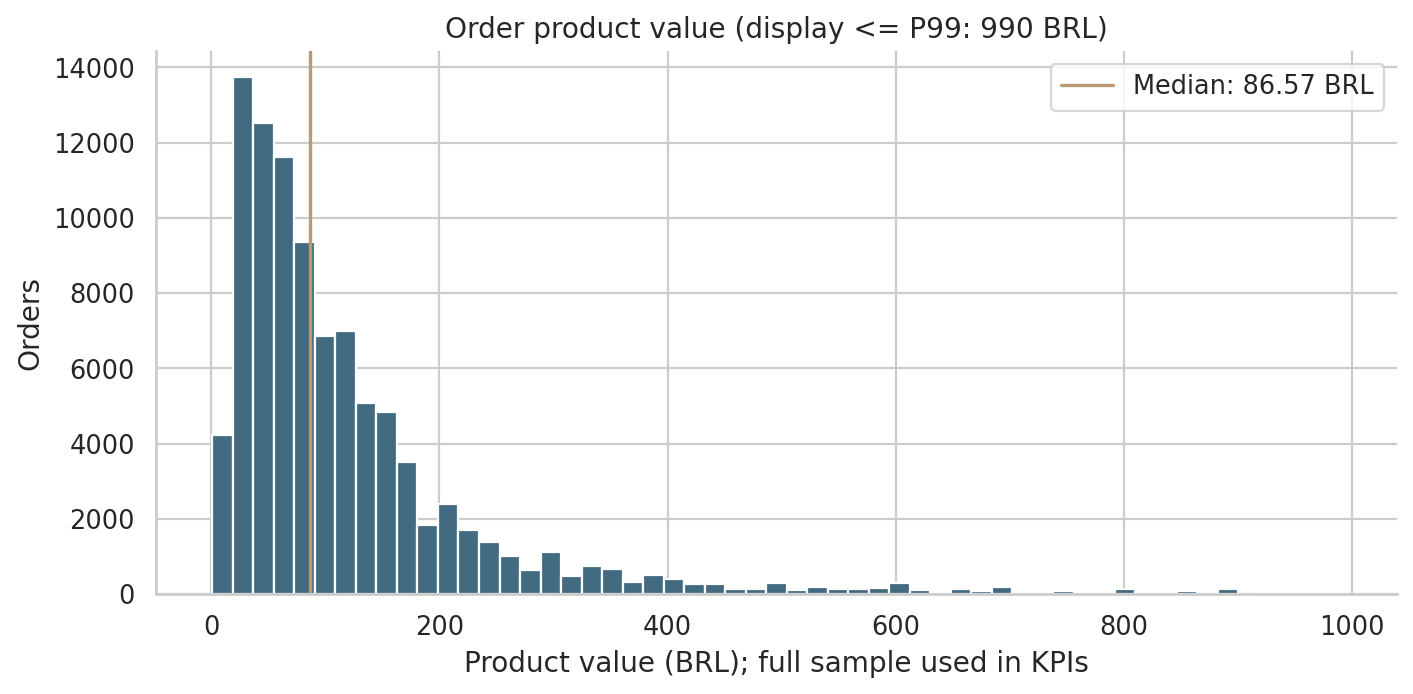

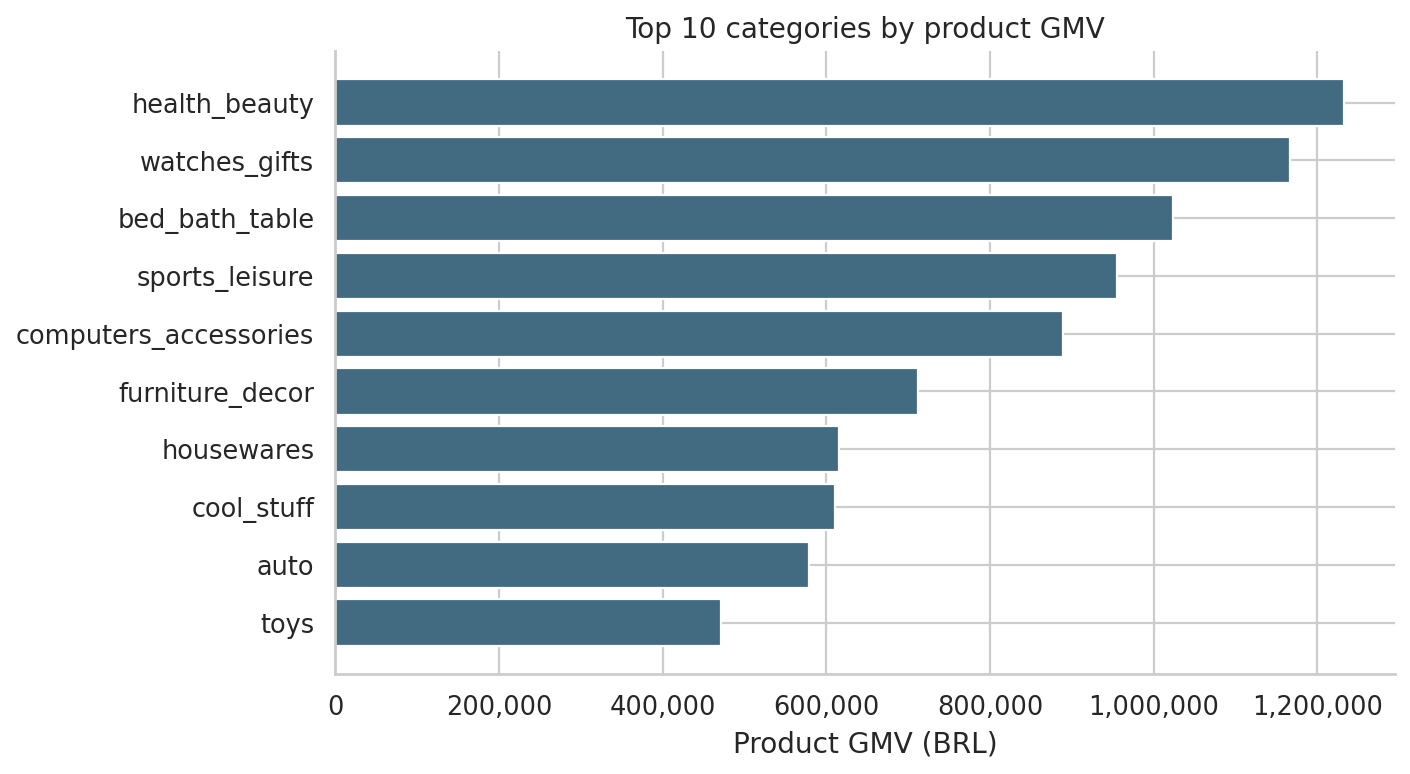

In [5]:
monthly = monthly_sales(sales)
categories = category_sales(tables, sales)
display(monthly.round(2))
display(categories.head(10).round(2))
assert abs(categories.revenue.sum() - sales.revenue.sum()) < 1e-6
for name in ['monthly_revenue.png', 'monthly_orders.png', 'order_value.png', 'top_categories.png']:
    display(Image(filename=str(ROOT / 'reports' / 'figures' / name), width=850))

## Клиенты: RFM и повторные заказы

Идентификатор покупателя — customer_unique_id. RFM использует день после последней покупки во **всей** таблице orders как snapshot. F-score = 1/2/3+, R и M — три уровня процентильных рангов с усреднением совпадений. Это описательная сегментация. Первая наблюдаемая покупка не обязательно первая покупка человека в жизни; доля повторных покупателей не является оценкой пожизненного удержания.

RFM snapshot: 2018-10-18
Repeat customer share: 3.00%


,segment,customers,orders,revenue,median_recency,aov,revenue_share_pct
3,Other one-time,50513,50513,5269663.91,221.0,104.32,39.86
2,Older one-time,30262,30262,4254285.24,457.0,140.58,32.18
5,Recent high value,9782,9782,2969140.21,128.0,303.53,22.46
0,Active repeat,1871,3988,520758.43,195.0,130.58,3.94
1,Lapsed repeat,813,1698,202508.22,441.0,119.26,1.53
4,Other repeat,117,235,5142.10,192.0,21.88,0.04


,orders,revenue,aov
buyer_type,,,
First observed order,93358,12838079.04,137.51
Repeat order,3120,383419.07,122.89


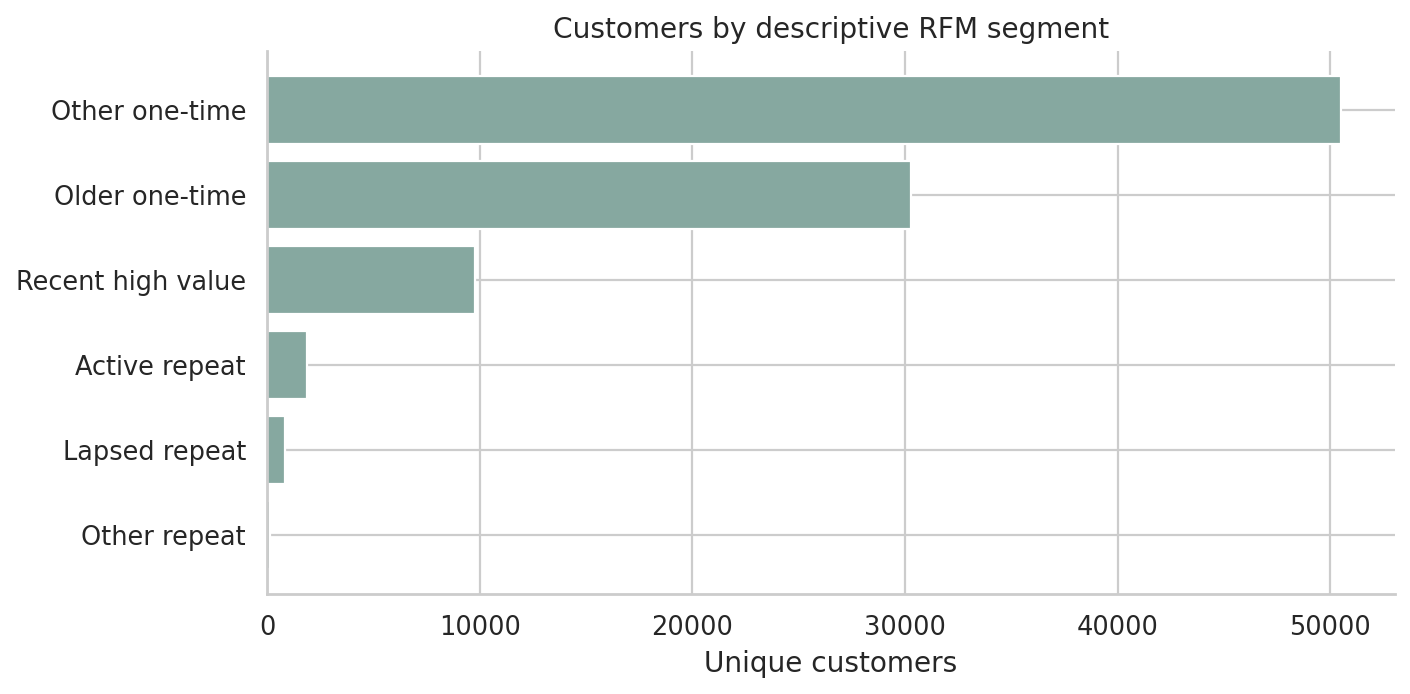

In [6]:
snapshot = tables['orders'].order_purchase_timestamp.max().normalize() + pd.Timedelta(days=1)
customers = customer_metrics(sales, snapshot)
segments = segment_summary(customers)
sequence = purchase_sequence(sales)
print('RFM snapshot:', snapshot.date())
print('Repeat customer share:', f'{(customers.frequency >= 2).mean():.2%}')
display(segments.round(2))
display(sequence.groupby('buyer_type').agg(orders=('order_id','size'), revenue=('revenue','sum'), aov=('revenue','mean')).round(2))
display(Image(filename=str(ROOT / 'reports/figures/customer_segments.png'), width=850))

## Доставка и оценки: одна гипотеза

H0: среди выбранных клиентов распределения оценок одинаковы для заказов с задержкой и без неё. H1: распределения различаются. Двусторонний Mann–Whitney U, α=0,05, поправка на связанные ранги. Это порядковая шкала, поэтому тест не трактуется как чистый тест медиан.

Основная выборка: delivered, известная дата получения, неотрицательный срок, известная оценка, ответ на отзыв после получения; первый подходящий заказ каждого уникального клиента. Размер эффекта = 2U/(n_late × n_on_time) − 1. Bootstrap CI разности средних — отдельное описательное измерение масштаба.

Исключение отзывов до получения меняет состав выборки, особенно для задержек. Дополнительно смотрим описательные результаты с такими отзывами. Остаются общие продавцы, маршруты и периоды; причинный эффект не установлен.

Bootstrap 95% CI of mean difference: [-0.6303684011114937, -0.5062313794117806]


,value
hypothesis,H0: score distributions identical; H1: differe...
method,"Mann-Whitney U, asymptotic, tie-corrected"
n_late,1855
n_on_time,86572
seed,42
bootstrap_resamples,1000
status,ok
u_statistic,60315532.0
p_value,0.0
rank_biserial,-0.248831


,is_late,n,mean_score
0,False,86536,4.288712
1,True,6211,2.265819


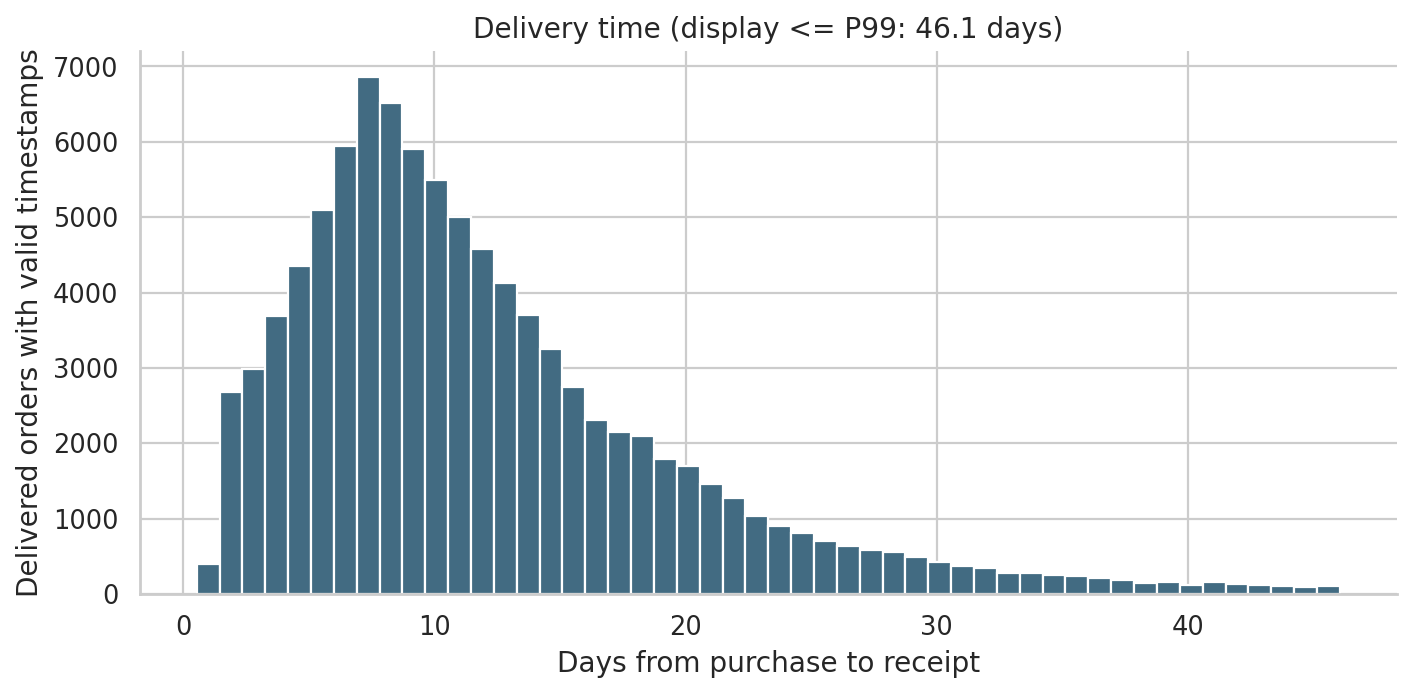

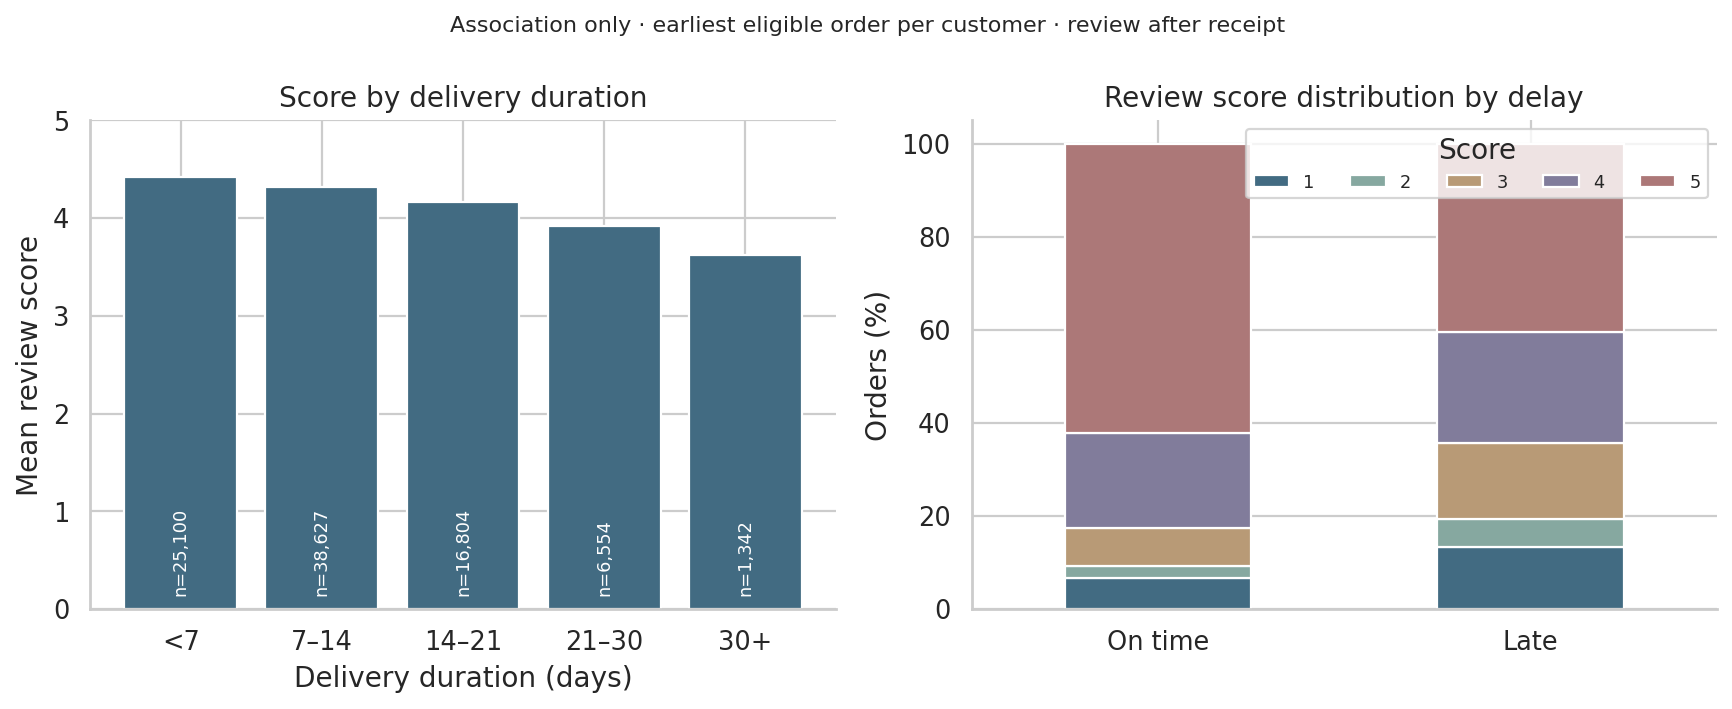

In [7]:
stats = delivery_hypothesis(sales)
display(pd.Series({k:v for k,v in stats.items() if not isinstance(v, (dict, list))}, name='value').to_frame())
print('Bootstrap 95% CI of mean difference:', stats.get('mean_difference_ci95'))
display(pd.DataFrame(stats['sensitivity_including_pre_receipt_reviews']))
for name in ['delivery_distribution.png', 'delivery_reviews.png']:
    display(Image(filename=str(ROOT / 'reports/figures' / name), width=950))

## SQL и Python: одинаковая выборка

Команды из корня проекта после запуска PostgreSQL: `python -m src.load_data`, затем `python -m src.verify_sql`. Последняя выполняет все аналитические SQL-файлы и сравнивает KPI, помесячные показатели, категории, клиентов и выборку отзывов с Python. Здесь показывается сохранённое свидетельство проверки; оно не означает, что при открытии notebook был запущен локальный сервер.

In [8]:
verification = ROOT / 'reports/sql_verification.json'
if verification.exists():
    display(json.loads(verification.read_text(encoding='utf-8')))
else:
    print('SQL not verified in this checkout yet. Run python -m src.verify_sql with PostgreSQL available.')
print((ROOT / 'sql/03_sales_analysis.sql').read_text(encoding='utf-8')[:1800])

SELECT COUNT(*) AS orders,COALESCE(SUM(revenue),0) AS product_gmv_brl,
 AVG(revenue) AS aov_brl,AVG(item_count) AS mean_items_per_order,
 COUNT(DISTINCT customer_unique_id) AS customers FROM olist.sales_orders;

-- Include zero-order internal months so LAG means previous calendar month.
WITH base AS (
 SELECT DATE_TRUNC('month',order_purchase_timestamp)::date AS month,
 SUM(revenue) AS revenue,COUNT(*) AS orders,SUM(item_count) AS items
 FROM olist.sales_orders GROUP BY 1
), calendar AS (
 SELECT GENERATE_SERIES(MIN(month),MAX(month),INTERVAL '1 month')::date AS month FROM base
), monthly AS (
 SELECT c.month,COALESCE(b.revenue,0) AS revenue,COALESCE(b.orders,0) AS orders,
 b.revenue/NULLIF(b.orders,0) AS aov,b.items::numeric/NULLIF(b.orders,0) AS items_per_order
 FROM calendar c LEFT JOIN base b USING(month)
)
SELECT *,100*(revenue/NULLIF(LAG(revenue) OVER(ORDER BY month),0)-1) AS revenue_mom_pct,
 100*(orders::numeric/NULLIF(LAG(orders) OVER(ORDER BY month),0)-1) AS orders_mom_pct
FR

{'engine': 'PostgreSQL 18.6 (PGlite 0.5.15) on wasm32-unknown-emscripten, compiled by emcc (Emscripten gcc/clang-like replacement + linker emulating GNU ld) 6.0.13 (e13ee988ce3d87a738dd8f3661d02223308c412a), 32-bit',
 'adapter': 'PGlite WebAssembly',
 'sql_files': [{'file': '02_data_quality.sql',
   'result_sets': 5,
   'rows': [8, 6, 789, 3, 1]},
  {'file': '03_sales_analysis.sql', 'result_sets': 3, 'rows': [1, 24, 74]},
  {'file': '04_customer_analysis.sql',
   'result_sets': 3,
   'rows': [93358, 1, 2]},
  {'file': '05_advanced_queries.sql', 'result_sets': 3, 'rows': [74, 2, 20]}],
 'native_postgresql_docker_tested': False,
 'limitations': ['SQL semantics checked via WASM; native PostgreSQL Docker and psycopg COPY not checked.'],
 'status': 'passed',
 'parity_checks': ['orders, GMV, AOV, mean item count, unique customers',
  'all monthly metrics including calendar gaps and MoM',
  'category GMV, item and order counts',
  'all customer frequencies, monetary values and recencies',
  '

## Бизнес-интерпретация и ограничения

Численные выводы, рекомендации и ограничения генерируются из расчётов в `reports/business_insights.md`. Нет данных о марже, возвратах, расходах и комиссиях; GMV не превращается в прибыль. Данные 2016–2018 гг. не описывают нынешний рынок. RFM ретроспективен, основан на финальных статусах. Проверку предложенных действий следует проводить отдельным экспериментом.

In [9]:
display(Markdown((ROOT / 'reports/business_insights.md').read_text(encoding='utf-8')))

# E-Commerce Sales Analytics: бизнес-результаты

Источник: реальные данные Olist, Kaggle. Валюта — бразильский реал (BRL), номинальные суммы.
Задача: описать продажи, повторные покупки и связь доставки с оценкой, определить направления проверки бизнес-гипотез.

## Выборка и KPI

Доставленные (`delivered`) заказы с позициями, даты покупки
15.09.2016–29.08.2018.
Snapshot RFM: 18.10.2018, день после последней покупки во всей исходной таблице заказов.

| Показатель | Значение |
|---|---:|
| Товарный GMV без доставки | 13,221,498.11 BRL |
| Доставленные заказы | 96,478 |
| Средний чек без доставки | 137.04 BRL |
| Среднее число позиций | 1.142 |
| Уникальные покупатели | 93,358 |
| Покупатели с ≥2 заказами | 2,801 (3.00%) |

GMV — сумма `order_items.price`, это стоимость товаров, а не комиссия или прибыль Olist.
Уникальная покупка — один `order_id`; покупатель — `customer_unique_id`, поскольку `customer_id` меняется между заказами.
Отменённые, недоступные и ещё не доставленные заказы исключены. Статус относится к финальному снимку.
Доставка и платежи не используются для подмены товарного GMV. Возвраты и фактический доход продавца не известны.

## Наблюдения и практические действия

1. В среднем 1.14 позиции на заказ. Проверить совместно покупаемые категории
   и возможность комплектов; сначала оценить покрытие и маржинальность, которых здесь нет.
2. Медиана стоимости заказа 86.57 BRL против среднего 137.04 BRL;
   P99 = 990.00 BRL. Для мониторинга корзины показывать медиану и перцентили вместе со средним;
   дорогие заказы не удалять автоматически как ошибки.
3. Категория `health_beauty` даёт 1,233,131.72 BRL (9.33% GMV).
   Первые пять категорий дают 39.83%. Начать проверку ассортимента и сервиса с этих категорий;
   высокий оборот сам по себе не означает высокую прибыль.
4. Только 3.00% покупателей совершили повторный доставленный заказ в наблюдаемом окне.
   Проверить повторные покупки по когортам и длине наблюдения до оценки удержания; это не оценка пожизненного оттока.
5. Пик GMV приходится на 2017-11: 987,765.37 BRL,
   7,289 заказов. Для планирования нагрузки исследовать этот период подробнее;
   причина пика без календаря кампаний не установлена. Крайние месяцы и конец периода могут быть неполными.
6. Среди 96,470 доставленных заказов с неотрицательным сроком и известной датой получения
   доля получения позже обещанного календарного дня — 6.77%,
   медианный срок — 10.22 дня.
   Проверить обещанные сроки по маршрутам и продавцам, прежде чем менять SLA.
7. RFM-сегменты описывают наблюдаемые R/F/M; таблица ниже показывает их масштаб.
   В условиях редких повторов F задан как 1/2/3+, R и M — три уровня по процентильным рангам.
   Сегменты можно использовать для пилотного эксперимента коммуникаций с контрольной группой.

## Сравнение сегментов

| segment           |   customers |   orders |          revenue |   median_recency |    aov |   revenue_share_pct |
|:------------------|------------:|---------:|-----------------:|-----------------:|-------:|--------------------:|
| Other one-time    |       50513 |    50513 |      5.26966e+06 |              221 | 104.32 |               39.86 |
| Older one-time    |       30262 |    30262 |      4.25429e+06 |              457 | 140.58 |               32.18 |
| Recent high value |        9782 |     9782 |      2.96914e+06 |              128 | 303.53 |               22.46 |
| Active repeat     |        1871 |     3988 | 520758           |              195 | 130.58 |                3.94 |
| Lapsed repeat     |         813 |     1698 | 202508           |              441 | 119.26 |                1.53 |
| Other repeat      |         117 |      235 |   5142.1         |              192 |  21.88 |                0.04 |

## Первый и повторный заказ

| buyer_type           |   orders |          gmv_brl |   aov_brl |
|:---------------------|---------:|-----------------:|----------:|
| First observed order |    93358 |      1.28381e+07 |    137.51 |
| Repeat order         |     3120 | 383419           |    122.89 |

Это описательное сравнение, не тест причинного эффекта повторной покупки.

## Доставка и отзывы: одна заранее выбранная гипотеза

H0: распределения оценок одинаковы у доставленных вовремя и с задержкой заказов.
H1: распределения различаются (двусторонняя проверка, α=0,05).
Выбран Mann–Whitney U с поправкой на связанные ранги: оценки порядковые, имеют пять значений.
В тесте 1,855 заказов с задержкой и 86,572 без задержки;
использован первый подходящий заказ каждого `customer_unique_id`, ответ на отзыв — после получения.
U = 60,315,532, p-value 4.53e-99;
ранговая бисериальная корреляция (late − on time) = -0.249.
Средняя оценка: 3.72 против 4.29;
медиана: 4 против 5.
Описательная разность средних -0.57, bootstrap 95% ДИ [-0.63; -0.51]
(1000 повторов, seed 42).
Доля оценок 1–2: 19.4% против 9.3%.
При α=0,05 отвергаем H0.
U не является чистым тестом разности медиан; разность средних приведена отдельно для масштаба.
Наблюдения независимы лишь приближённо: остаются общие продавцы, регионы, сезонность.
Это связь, причинное влияние задержки не установлено; отзыв отражает и другие стороны заказа.

Чувствительность к исключению отзывов до получения (первый подходящий заказ клиента,
включены все известные оценки при валидной доставке; дополнительный p-value не рассчитывается):

| is_late   |     n |   mean_score |
|:----------|------:|-------------:|
| False     | 86536 |        4.289 |
| True      |  6211 |        2.266 |

`is_late=True` — задержка. Исключение отзывов до получения особенно заметно для задержанных заказов:
такой отзыв мог описывать неполученный товар. Основной тест относится к отзывам после получения,
а не ко всем заказам; переносить его размер эффекта на всю базу нельзя.

## Качество данных и принятые решения

| check                            |   count |
|:---------------------------------|--------:|
| delivered_missing_timestamp      |       8 |
| delivery_before_purchase         |       0 |
| carrier_before_purchase          |     166 |
| approval_before_purchase         |       0 |
| orders_without_items             |     775 |
| orders_without_payments          |       1 |
| payment_total_mismatch_gt_1_cent |     303 |
| orders_multiple_review_rows      |     547 |
| review_id_reused                 |     814 |
| products_missing_category        |     610 |
| categories_without_translation   |       2 |
| selected_review_before_receipt   |    4654 |
| zero_price_items                 |       0 |
| zero_payment_rows                |       9 |

Пустые тексты отзывов не означают отсутствие оценки. Пустые характеристики товаров и отсутствующие
категории не заполняются средними; для категорий используется `unknown`, а при отсутствии перевода — исходное имя.
Отсутствующие даты доставки не восстанавливаются: заказ входит в продажи, но не в анализ длительности/задержки.
Если отзывов несколько, выбран последний по времени ответа с детерминированным разрешением совпадений.
Отзыв до получения исключается из статистической выборки. Денежные расхождения с платежами остаются диагностикой.
Число категорийных заказов не аддитивно: заказ может содержать несколько категорий.

## Ограничения

- Наблюдательный срез одной платформы Бразилии 2016–2018 гг.; результаты не отражают текущий рынок.
- Конец окна цензурирован: недавние покупки могли ещё не стать доставленными; месячный спад не доказывает падение спроса.
- RFM рассчитан ретроспективно по финальным статусам, это не историческая модель, обученная на информации на дату покупки.
- Повторные покупки за пределами платформы и окна не видны; F — число заказов, не число дней покупки.
- Нет себестоимости, комиссий, возвратов, маркетинговых затрат и налогов; прибыль и ROI не рассчитываются.
- Оценки оставляют не все клиенты. Последний отзыв — обоснованное правило агрегации, но оно влияет на выборку.
- Даты исходные, без часового пояса; для задержки сравниваются календарные дни. Ничего не конвертируется в UTC.
- Bootstrap ДИ и p-value не учитывают кластеризацию продавцов и маршрутов; вывод требует проверки устойчивости.
- Рекомендации — направления проверки, а не обещание роста продаж.

Все значения сформированы `python -m src.run_analysis`. Подробные таблицы — `reports/*.csv`,
полный профиль исходных таблиц — `reports/data_profile.json`; воспроизводимость источника — `reports/source_manifest.json`.
